In [8]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict,Literal
from IPython.display import Image, display



In [2]:
class QuadState(TypedDict):

  a: int
  b: int
  c: int 

  equation: str
  discriminant: float
  result: str

In [19]:
def show_equation(state: QuadState):
  equation = f"{state["a"]}x2{state["b"]}x{state["c"]}"

  return {'equation':equation}

def calculate_discriminant(state: QuadState):
  discriminant = state["b"]**2 - (4*state["a"] * state["c"])

  return {'discriminant': discriminant}

def real_roots(state:QuadState):
  root1 = (-state["b"] + state["discriminant"]**0.5)/(2*state["a"])
  root2 = (-state["b"] - state["discriminant"]**0.5)/(2*state["a"])

  result = f"The roots are {root1} and {root2}"


def equal_roots(state:QuadState):
  root = (-state["b"] /(2*state["a"]*2))
 

  result = f"The only root is {root}"

def imaginary_roots(state: QuadState):
  result = f"No Real Roots" 

def check_condn(state: QuadState) -> Literal["real_roots","equal_roots","imaginary_roots"] :
  if(state["discriminant"]>0):
    return "real_roots"
  elif state["discriminant"] == 0:
    return "equal_roots"
  else:
    return "imaginary_roots"


In [25]:
graph = StateGraph(QuadState)

graph.add_node('show_equation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('real_roots',real_roots)
graph.add_node('equal_roots',equal_roots)
graph.add_node('imaginary_roots',imaginary_roots)


graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_discriminant')
graph.add_conditional_edges('calculate_discriminant',check_condn)
graph.add_edge('real_roots',END)
graph.add_edge('imaginary_roots',END)
graph.add_edge('equal_roots',END)




workflow = graph.compile()


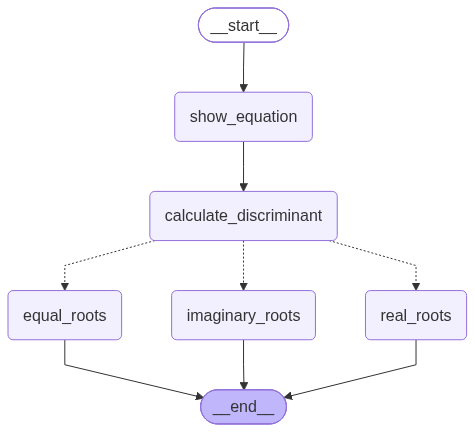

In [26]:
workflow

In [27]:
initial_state = {
  'a': 4,
  'b': -5,
  'c': -4
}

workflow.invoke(initial_state)

{'a': 4, 'b': -5, 'c': -4, 'equation': '4x2-5x-4', 'discriminant': 89}